In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem1
import optimiser_new

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [2]:
env = problem1.environment(sigma_s = 1, b2 = 1e-3, a1 = -5)

In [3]:
np.random.seed(123)

nsims = 100

env.simulate(nsims, env.optimal_strag)

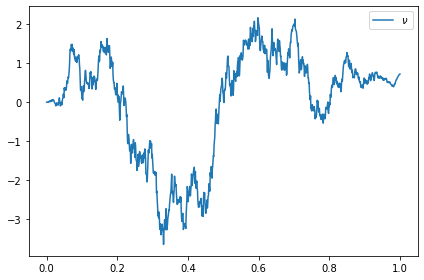

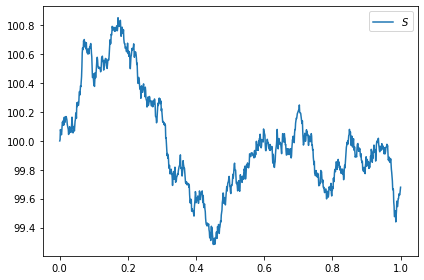

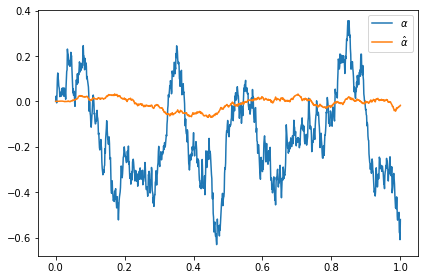

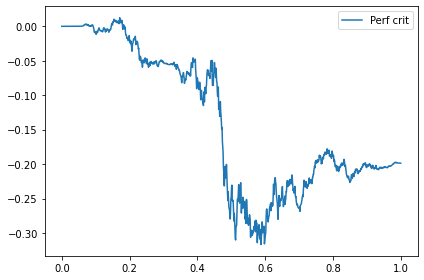

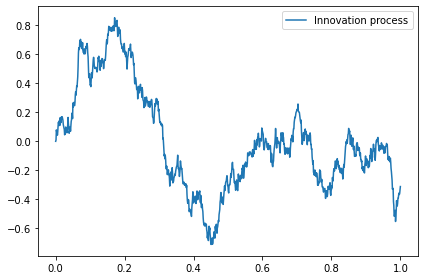

In [4]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.S[:,nsim], label=r'$S$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.alpha[:,nsim], label=r'$\alpha$')
plt.plot(env.timesteps, env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.crit[:,nsim], label=r'Perf crit')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.innov[:,nsim], label=r'Innovation process')
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
np.random.seed(456)
dim = 2
order = 3
optimiser_1 = optimiser_new.Optimiser(env, order = order, poly_deg = 5)

In [6]:
np.random.seed(123)
trunc_lev = 3
trunc_lev_1 = 6

#optimiser_1.train(trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1, method='BFGS')

#F = optimiser_1.F

F = np.array([ 1.80932630e+03, -2.43819788e+03,  1.82406510e+01,  9.58148236e+00,
        7.92795269e+00, -4.16435584e+00, -4.26124684e+00, -1.32462609e+01,
       -5.38919707e+00,  1.80969750e+01,  1.65505738e+01, -5.86290942e+00,
       -6.43154398e-01, -3.74608187e+00,  1.70448943e+00])

F = ta.sig_to_tensor(F, dim = dim, order = order)

strag_sig = problem1.sig_strag_dot(F, order = trunc_lev_1)

In [7]:
optimiser_1.W_sig_expected

Tensor([1.0, [1.0, 0.0], [[0.5, 0.0], [0.0, 0.5]], [[[0.16666666666666666, 0.0], [0.0, 0.25]], [[0.0, 0.0], [0.25, 0.0]]]])

In [8]:
F_new = np.array([ 1.80932630e+03, -2.43819788e+03,  1.82406510e+01,  9.58148236e+00,
        7.92795269e+00, -4.16435584e+00, -4.26124684e+00, -1.32462609e+01,
       -5.38919707e+00,  1.80969750e+01,  1.65505738e+01, -5.86290942e+00,
       -6.43154398e-01, -3.74608187e+00,  1.70448943e+00])

In [9]:
F.flatten()

array([ 1.80932630e+03, -2.43819788e+03,  1.82406510e+01,  9.58148236e+00,
        7.92795269e+00, -4.16435584e+00, -4.26124684e+00, -1.32462609e+01,
       -5.38919707e+00,  1.80969750e+01,  1.65505738e+01, -5.86290942e+00,
       -6.43154398e-01, -3.74608187e+00,  1.70448943e+00])

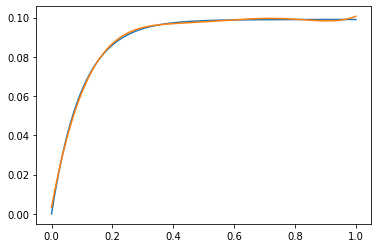

In [10]:
sigma_alpha_hat = env.b1*env.V_alpha/env.sigma_s
p_coef = np.polyfit(env.timesteps, sigma_alpha_hat, deg = 5)
sigma_alpha_hat_fit = np.polyval(p_coef, env.timesteps)
plt.plot(env.timesteps, sigma_alpha_hat)
plt.plot(env.timesteps, sigma_alpha_hat_fit)

In [11]:
p_coef_reversed = p_coef[::-1]

In [12]:
f_s = ta.word((),dim)*env.alpha0 + F*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
word = (1,)
for k in range(len(p_coef_reversed)):
    word_tensor = ta.word(word,dim)
    f_s += word_tensor*p_coef_reversed[k]
    word = (0,) + word
exp_a1 = (ta.word((0,),dim)*env.a1).exp(MAX_ITER = 200, MAX_LEVEL = trunc_lev)
f_s = f_s*exp_a1
f_s = f_s*(ta.word((0,),dim)*env.b1)
f_s += ta.word((1,),dim)*env.sigma_s
f_s += ta.word((0,),dim)*env.b0
f_s += F*(ta.word((0,),dim)*env.b2)
f_s += ta.word((),dim)*env.S0 
f_s = f_s.truncate(trunc_lev)

f_alpha = ta.word((),dim)*env.alpha0 + F*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
word = (1,)
for k in range(len(p_coef_reversed)):
    word_tensor = ta.word(word,dim)
    f_alpha += word_tensor*p_coef_reversed[k]
    word = (0,) + word
exp_a1 = (ta.word((0,),dim)*env.a1).exp(MAX_ITER = 200, MAX_LEVEL = trunc_lev_1)
f_alpha = f_alpha*exp_a1
f_alpha = f_alpha.truncate(trunc_lev_1)

M_max = 2*F.order
p_perf = -F.shuffle(F, max_order = M_max)
p_perf = p_perf*(optimiser_1.e1*optimiser_1.env.k)
M_max = (F*optimiser_1.e1).order + F.order
p_perf += ((F*optimiser_1.e1).shuffle(F, max_order = M_max))*(optimiser_1.e1*(optimiser_1.env.b2 - 2*optimiser_1.env.theta1))
M_max = (F*optimiser_1.e1).order + trunc_lev_1
p_perf += ((F*optimiser_1.e1).shuffle(f_alpha, max_order = M_max))*(optimiser_1.e1*optimiser_1.env.b1)
p_perf += ((F*optimiser_1.e1)*(optimiser_1.e1*optimiser_1.env.b0))
F_prod_e1 = F*optimiser_1.e1
M_max = 2*F_prod_e1.order
p_perf -= (F_prod_e1.shuffle(F_prod_e1, max_order = M_max))*(optimiser_1.e1*optimiser_1.env.theta2)

In [13]:
np.random.seed(123)

nsims = 100

env.simulate(nsims, strag_sig)

In [14]:
f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = 5)

S_sig = np.zeros((env.Nt+1,nsims))
alpha_hat_sig = np.zeros((env.Nt+1,nsims))
perf_hist = np.zeros((env.Nt+1,nsims))

S_sig = f_s_sig(env)
alpha_hat_sig = f_alpha_sig(env)
perf_hist = f_perf_crit(env)

# for it in range(env.Nt+1):
#     S_sig[it,:] = f_s_sig(env,it)
#     alpha_hat_sig[it,:] = f_alpha_sig(env,it)
#     perf_hist[it,:] = f_perf_crit(env,it)
#     #S_sig[it,:] = strag_sig(env,it)

../src\problem1.py:253: FutureWarning: The input object of type 'Tensor' is an array-like implementing one of the corresponding protocols (`__array__`, `__array_interface__` or `__array_struct__`); but not a sequence (or 0-D). In the future, this object will be coerced as if it was first converted using `np.array(obj)`. To retain the old behaviour, you have to either modify the type 'Tensor', or assign to an empty array created with `np.empty(correct_shape, dtype=object)`.
  strag[1:, nsim] = np.array([F.dot(ta.sig_to_tensor(innov_sig_flat[it,:], 2, order)) for it in range(env.Nt)])
../src\problem1.py:253: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  strag[1:, nsim] = np.array([F.dot(ta.sig_to_tensor(innov_sig_flat[it,:], 2, order)) for it in range(env.Nt)])


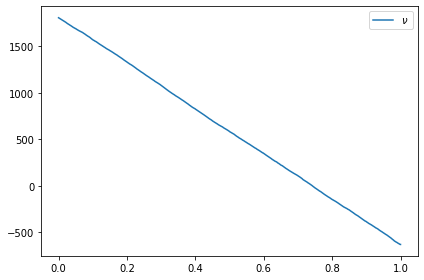

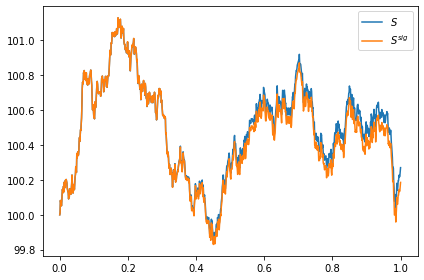

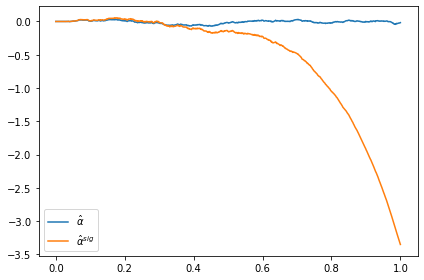

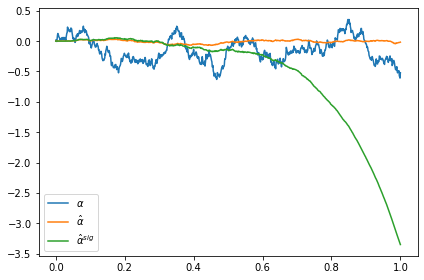

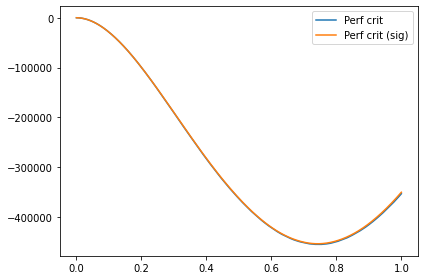

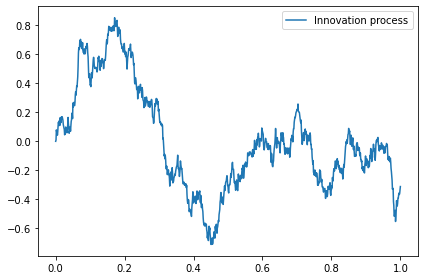

In [15]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.S[:,nsim], label=r'$S$')
plt.plot(env.timesteps, S_sig[:,nsim], label=r'$S^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.plot(env.timesteps, alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.alpha[:,nsim], label=r'$\alpha$')
plt.plot(env.timesteps, env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.plot(env.timesteps, alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps, perf_hist[:,nsim], label=r'Perf crit (sig)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.innov[:,nsim], label=r'Innovation process')
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
env.wealth[-1,:].mean()

-585.0134802215111

In [17]:
env.crit[-1,:].mean()

-356089.4870794828